In [174]:
import numpy as np
import matplotlib.pyplot as plt

In [175]:
def gauss_jacobi(A, b, x0, tol=0.5e-6, max_iter=100):
  n = len(b)
  x = x0.copy()
  x_new = np.zeros_like(x)
  errors = []
  for k in range(max_iter):
    for i in range(n):
      sum_ = sum(A[i][j] * x[j] for j in range(n) if j != i)
      x_new[i] = (b[i] - sum_) / A[i][i]
    error = np.linalg.norm(x_new - x, ord=np.inf)
    errors.append(error)
    print(f"Iteration {k+1}: x = {x_new}, Error = {error}")
    if error < tol:
      break
    x[:] = x_new    # Update x for next iteration
  return x_new, errors

In [176]:
def rate_of_convergence(errors):
  rates = []
  for i in range(1, len(errors)-1):
    rate = np.log(errors[i+1] / errors[i] / np.log(errors[i] / errors[i-1]))
    rates.append(rate)
  return rates

In [177]:
# Example System
# A = np.array([[10, -1, 2, 0],
#               [-1, 11, -1, 3],
#               [2, -1, 10, -1],
#               [0, 3, -1, 8]], dtype=float)
A = np.array([[5, -1, 1],
              [2, 8, -1],
              [-4, 1, 10]], dtype=float)
b = np.array([14, -7, 21], dtype=float)
x0 = np.zeros_like(b)

In [178]:
# Solve using Gauss-Jacobi
solution, errors = gauss_jacobi(A, b, x0)

Iteration 1: x = [ 2.8   -0.875  2.1  ], Error = 2.8
Iteration 2: x = [ 2.205  -1.3125  3.3075], Error = 1.2075
Iteration 3: x = [ 1.876     -1.0128125  3.11325  ], Error = 0.3290000000000002
Iteration 4: x = [ 1.9747875  -0.95484375  2.95168125], Error = 0.16156874999999982
Iteration 5: x = [ 2.018695   -0.99973672  2.98539938], Error = 0.04489296875000004
Iteration 6: x = [ 2.00297278 -1.00649883  3.00745167], Error = 0.0220522968750001
Iteration 7: x = [ 1.9972099  -0.99981174  3.001839  ], Error = 0.0066870917968751
Iteration 8: x = [ 1.99966985 -0.9990726   2.99886513], Error = 0.002973861679687495
Iteration 9: x = [ 2.00041245 -1.00005932  2.9997752 ], Error = 0.000986721127929635
Iteration 10: x = [ 2.0000331  -1.00013121  3.00017091], Error = 0.00039571190654275057
Iteration 11: x = [ 1.99993957 -0.99998691  3.00002636], Error = 0.000144553983368656
Iteration 12: x = [ 1.99999735 -0.9999816   2.99997452], Error = 5.777148456176384e-05
Iteration 13: x = [ 2.00000878 -1.00000252 

In [179]:
# Compute rate of convergence
roc = rate_of_convergence(errors)
print("Rate of Convergence: ", roc)

Rate of Convergence:  [np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan)]


/tmp/ipykernel_1534/2962329949.py:4: RuntimeWarning: invalid value encountered in log
  rate = np.log(errors[i+1] / errors[i] / np.log(errors[i] / errors[i-1]))


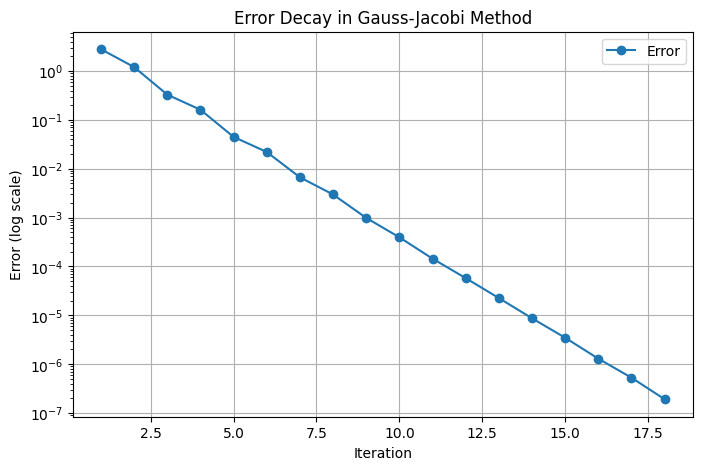

In [180]:
# Plot the error decay
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(errors)+1), errors, marker='o', linestyle='-', label='Error')
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Error (log scale)')
plt.title('Error Decay in Gauss-Jacobi Method')
plt.legend()
plt.grid(True)
plt.show()